# 1. Постановка задачи

## 1.1. Бизнес-постановка задачи

Спам-сообщения могут содержать нежелательную рекламу, сомнительные предложения и ссылки на потенциально опасные ресурсы. Ручная проверка большого количества сообщений требует времени, поэтому автоматическое определение спама может быть полезно для повышения удобства и безопасности пользователей.

Цель проекта — рассмотреть возможность создания программы, которая автоматически определяет, относится ли SMS-сообщение к спаму или является обычным сообщением.

## 1.2. Постановка ML-задачи

Для решения задачи предлагается использовать машинное обучение. Задача относится к бинарной классификации, поскольку необходимо распределить сообщения по двум классам:

- `spam` — спам-сообщение;
- `ham` — обычное сообщение.

В качестве входных данных используется текст SMS, а правильный класс сообщения служит целевым признаком. В дальнейшем на этих данных можно обучить модель, которая будет определять класс новых сообщений.

## 1.3. Описание набора данных

Для исследования выбран открытый набор данных SMS Spam Collection из репозитория UCI Machine Learning Repository.

Набор содержит 5574 SMS-сообщения на английском языке, размеченных как спам или обычные сообщения. Данные представлены в текстовом файле, в котором каждой записи соответствуют метка класса и текст сообщения.

Набор данных подходит для поставленной задачи, поскольку содержит как исходные сообщения, так и информацию об их классе. Это позволяет изучить распределение классов, исследовать особенности текстов и подготовить данные для возможного последующего обучения модели.

Источник данных: https://archive.ics.uci.edu/dataset/228/sms+spam+collection

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# загружаю данные из файла
df = pd.read_csv(
    '/content/SMSSpamCollection',
    sep='\t',
    header=None,
    names=['label', 'message']
)

# показываю первые 5 сообщений
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


# 2. Выбор метрик качества

Для оценки качества будущей модели выбраны метрики Recall и F1-score.

Recall показывает, какую долю настоящих спам-сообщений модель смогла обнаружить. Эта метрика важна, поскольку пропуск спама снижает эффективность фильтрации. F1-score учитывает одновременно Precision и Recall, позволяя оценить баланс между обнаружением спама и количеством обычных сообщений, ошибочно отнесённых к спаму.

In [4]:

# сколько строк и столбцов
print("Размер таблицы:", df.shape)

# проверяю типы данных
print("\nТипы столбцов:")
print(df.dtypes)

# проверяю пропуски
print("\nПропущенные значения:")
print(df.isnull().sum())

# проверяю дубликаты
print("\nКоличество дубликатов:", df.duplicated().sum())

# считаю сообщения каждого класса
print("\nКоличество сообщений каждого класса:")
print(df['label'].value_counts())


Размер таблицы: (5572, 2)

Типы столбцов:
label      object
message    object
dtype: object

Пропущенные значения:
label      0
message    0
dtype: int64

Количество дубликатов: 403

Количество сообщений каждого класса:
label
ham     4825
spam     747
Name: count, dtype: int64


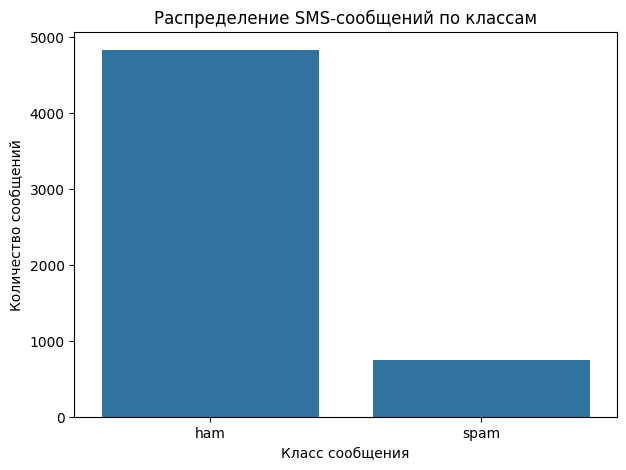

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='label')

plt.title('Распределение SMS-сообщений по классам')
plt.xlabel('Класс сообщения')
plt.ylabel('Количество сообщений')

plt.show()

### Анализ структуры данных и распределения классов

В результате загрузки набора данных было получено 5572 SMS-сообщения и два столбца: `label` и `message`. Первый столбец содержит класс сообщения, второй — его текст.

В ходе проверки не было обнаружено пропущенных значений. При этом было выявлено 403 дубликата, которые необходимо дополнительно рассмотреть перед дальнейшим использованием данных.

На диаграмме распределения классов видно, что набор содержит 4825 обычных сообщений и 747 спам-сообщений. Таким образом, обычные сообщения составляют приблизительно 86,6% данных, а спам — 13,4%.

Следовательно, в наборе наблюдается дисбаланс классов. Это необходимо учитывать при дальнейшем построении модели, поскольку высокая общая точность не обязательно означает, что модель хорошо обнаруживает спам. Для оценки качества классификации целесообразно использовать Recall и F1-score.

        count    mean    std   min    25%    50%    75%    max
label                                                         
ham    4825.0   71.48  58.44   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.67  28.87  13.0  133.0  149.0  157.0  223.0


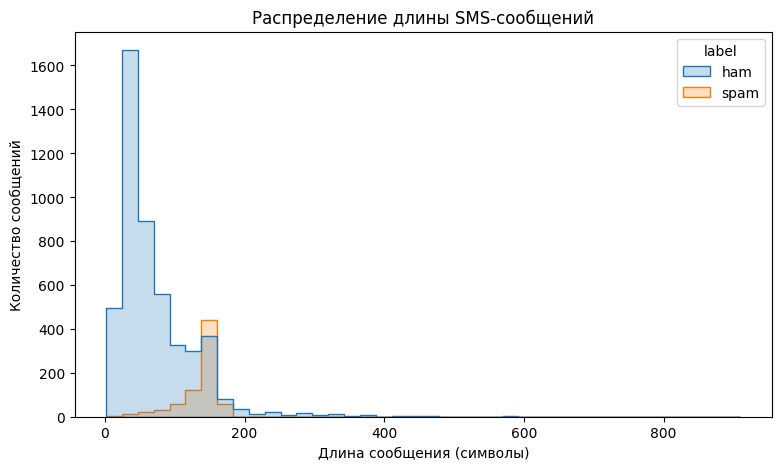

In [6]:

# добавляю столбец с длиной каждого сообщения
df['message_length'] = df['message'].str.len()

# считаю статистики длины сообщений для каждого класса
print(
    df.groupby('label')['message_length']
      .describe()
      .round(2)
)

# строю гистограмму
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='message_length',
    hue='label',
    bins=40,
    element='step',
    stat='count',
    common_norm=False
)

plt.title('Распределение длины SMS-сообщений')
plt.xlabel('Длина сообщения (символы)')
plt.ylabel('Количество сообщений')

plt.show()


Анализ длины сообщений

Для каждого SMS-сообщения была рассчитана длина в символах. Статистики длины по классам показали существенные различия:
- Средняя длина обычных сообщений (ham) составляет 71,5 символа, медиана — 52 символа.
- Средняя длина спам-сообщений — 138,7 символа, медиана — 149 символов.
Спам-сообщения в среднем почти в два раза длиннее обычных и имеют значительно меньший разброс длин. На гистограмме распределения видно, что основная масса обычных сообщений сосредоточена в диапазоне до 100 символов, тогда как спам-сообщения образуют выраженный пик в районе 130–160 символов.

Такое различие в длине может быть использовано в дальнейшем как один из простых признаков при построении модели классификации.

In [7]:

from collections import Counter
import re

# разделяю сообщения на слова и приводю их к нижнему регистру
def get_words(text):
    return re.findall(r'\b[a-z]+\b', text.lower())

# объединяю сообщения каждого класса и считаю слова
ham_words = Counter(
    word
    for message in df[df['label'] == 'ham']['message']
    for word in get_words(message)
)

spam_words = Counter(
    word
    for message in df[df['label'] == 'spam']['message']
    for word in get_words(message)
)

# вывожу 15 самых частых слов
print("Самые частые слова в обычных сообщениях:")
print(ham_words.most_common(15))

print("\nСамые частые слова в спаме:")
print(spam_words.most_common(15))


Самые частые слова в обычных сообщениях:
[('i', 2960), ('you', 1948), ('to', 1562), ('the', 1133), ('a', 1070), ('u', 1033), ('and', 858), ('in', 823), ('me', 777), ('my', 754), ('is', 739), ('it', 718), ('that', 560), ('of', 526), ('for', 507)]

Самые частые слова в спаме:
[('to', 691), ('a', 380), ('call', 355), ('you', 297), ('your', 264), ('free', 224), ('the', 206), ('for', 204), ('now', 199), ('or', 188), ('u', 174), ('txt', 163), ('is', 158), ('on', 145), ('ur', 144)]


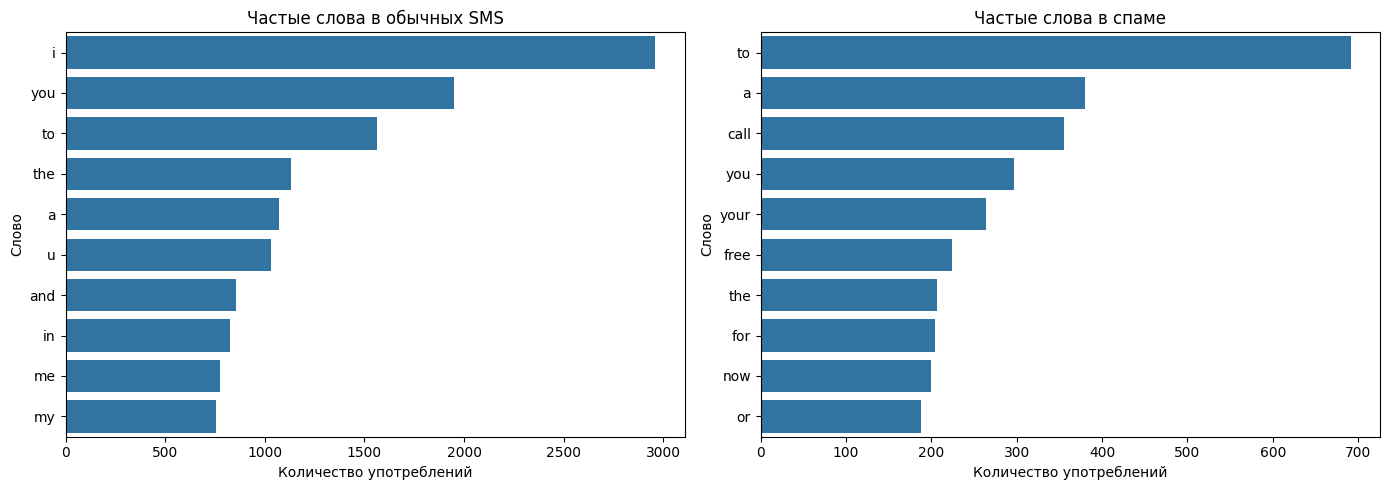

In [8]:

# получаб 10 самых частых слов в каждом классе
ham_top = ham_words.most_common(10)
spam_top = spam_words.most_common(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# график для обычных сообщений
sns.barplot(
    x=[count for word, count in ham_top],
    y=[word for word, count in ham_top],
    ax=axes[0]
)
axes[0].set_title('Частые слова в обычных SMS')
axes[0].set_xlabel('Количество употреблений')
axes[0].set_ylabel('Слово')

# график для спама
sns.barplot(
    x=[count for word, count in spam_top],
    y=[word for word, count in spam_top],
    ax=axes[1]
)
axes[1].set_title('Частые слова в спаме')
axes[1].set_xlabel('Количество употреблений')
axes[1].set_ylabel('Слово')

plt.tight_layout()
plt.show()


### Анализ наиболее часто встречающихся слов

Для дополнительного исследования текстовых данных были подсчитаны наиболее часто встречающиеся слова в обычных сообщениях и спаме. Результаты представлены в виде двух столбчатых диаграмм.

В обычных сообщениях наиболее часто встречаются слова `i`, `you`, `to`, `the`, `a` и `u`. Это преимущественно распространённые слова, которые используются в повседневной переписке.

В спам-сообщениях часто встречаются слова `to`, `a`, `call`, `you`, `your`, `free`, `now` и `txt`. Некоторые из них могут быть связаны с рекламными предложениями и призывами к действию.

Таким образом, предварительный анализ показал, что частота употребления отдельных слов может быть полезна для различения обычных сообщений и спама. Однако наличие конкретного слова само по себе не позволяет однозначно определить класс сообщения. В дальнейшем можно использовать частоты слов как признаки модели машинного обучения.

In [9]:

# смотрю несколько повторяющихся сообщений
duplicates = df[df.duplicated(keep=False)]

print("Всего строк, относящихся к дубликатам:", len(duplicates))
print("\nПримеры повторяющихся сообщений:")

display(
    duplicates[['label', 'message']]
    .sort_values('message')
    .head(10)
)


Всего строк, относящихся к дубликатам: 684

Примеры повторяющихся сообщений:


,label,message
505,spam,+123 Congratulations - in this week's competit...
2124,spam,+123 Congratulations - in this week's competit...
2344,ham,1) Go to write msg 2) Put on Dictionary mode 3...
1373,ham,1) Go to write msg 2) Put on Dictionary mode 3...
2163,ham,1) Go to write msg 2) Put on Dictionary mode 3...
1050,spam,18 days to Euro2004 kickoff! U will be kept in...
2719,spam,18 days to Euro2004 kickoff! U will be kept in...
2044,spam,4mths half price Orange line rental & latest c...
389,spam,4mths half price Orange line rental & latest c...
1779,ham,7 wonders in My WORLD 7th You 6th Ur style 5th...


### Анализ дубликатов

В наборе данных обнаружено 403 повторные копии строк. При этом общее количество строк, участвующих в группах дубликатов с учётом первых вхождений, составляет 684.

Дубликаты встречаются как среди обычных сообщений, так и среди спама. Это может быть связано с тем, что одинаковые сообщения отправлялись или сохранялись несколько раз.

Перед обучением модели целесообразно рассмотреть удаление повторяющихся записей, поскольку они могут влиять на распределение данных и результаты оценки качества модели. При этом на этапе разведочного анализа исходный набор данных сохраняется без изменений.

# 4. Общие выводы по результатам EDA

В ходе работы был проведён разведочный анализ набора данных SMS Spam Collection, предназначенного для исследования задачи обнаружения спам-сообщений.

В процессе анализа были изучены структура данных, распределение классов, длина сообщений, наиболее часто встречающиеся слова и наличие дубликатов.

В наборе содержится 5572 сообщения: 4825 обычных сообщений и 747 спам-сообщений. Пропущенные значения отсутствуют, однако было обнаружено 403 повторные копии строк. Также установлено, что спам-сообщения в среднем длиннее обычных. Анализ частоты слов показал, что в спаме часто встречаются слова, связанные с рекламными предложениями и призывами к действию, например `free`, `call`, `now` и `txt`.

Полученные результаты показывают, что выбранный набор данных подходит для дальнейшего исследования задачи бинарной классификации. При этом необходимо учитывать дисбаланс классов и наличие повторяющихся записей.

Перед возможным обучением модели целесообразно удалить дубликаты, исследовать особенности текстов и преобразовать сообщения в числовые признаки, которые можно использовать в алгоритмах машинного обучения. Для оценки качества будущей модели были выбраны метрики Recall и F1-score, позволяющие оценить способность обнаруживать спам и учитывать ошибки классификации.

Таким образом, поставленная цель разведочного анализа достигнута: изучены основные характеристики набора данных, построены визуализации и определены особенности, которые необходимо учитывать при дальнейшем решении задачи.